# 02 · How sensitive is coverage to the SBERT threshold?

There is no labelled ground truth for "is this skill taught", so precision /
recall can't be computed. Instead this notebook asks a simpler question: how
much does the coverage estimate move as the semantic cutoff changes?

Only skills without a lexical match are affected by the threshold; the 68
lexical matches are fixed. Runs entirely from `results/skill_coverage.csv`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight"})
BLUE, ORANGE, GREEN, RED = "#1f4e79", "#d68910", "#2d7a4f", "#b03a2e"

df = pd.read_csv("../results/skill_coverage.csv")
lexical = df[df["match_step"] < 3]
semantic_pool = df[df["match_step"] == 3]
print(f"{len(df)} skills: {len(lexical)} lexical matches (fixed), {len(semantic_pool)} decided by SBERT")

165 skills: 68 lexical matches (fixed), 97 decided by SBERT


In [2]:
thresholds = [0.50, 0.55, 0.60, 0.65, 0.70, 0.75, 0.80]
rows = []
for t in thresholds:
    sem = int((semantic_pool["similarity_score"] >= t).sum())
    total = len(lexical) + sem
    rows.append({"threshold": t, "semantic_covered": sem, "total_covered": total,
                 "missing": len(df) - total, "coverage_pct": round(100 * total / len(df), 1)})
sens = pd.DataFrame(rows)
sens.to_csv("../results/threshold_sensitivity.csv", index=False)
sens

,threshold,semantic_covered,total_covered,missing,coverage_pct
0,0.50,55,123,42,74.5
1,0.55,50,118,47,71.5
2,0.60,38,106,59,64.2
3,0.65,30,98,67,59.4
4,0.70,21,89,76,53.9
5,0.75,11,79,86,47.9
6,0.80,6,74,91,44.8


In [3]:
by_domain = []
for t in thresholds:
    for d, sub in df.groupby("domain"):
        covered = (sub["match_step"] < 3).sum() + ((sub["match_step"] == 3) & (sub["similarity_score"] >= t)).sum()
        by_domain.append({"threshold": t, "domain": d, "coverage_pct": round(100 * covered / len(sub), 1)})
by_domain = pd.DataFrame(by_domain)
by_domain.pivot(index="threshold", columns="domain", values="coverage_pct")

domain,CBE,CSE
threshold,,
0.50,89.1,56.2
0.55,88.0,50.7
0.60,82.6,41.1
0.65,76.1,38.4
0.70,67.4,37.0
0.75,57.6,35.6
0.80,53.3,34.2


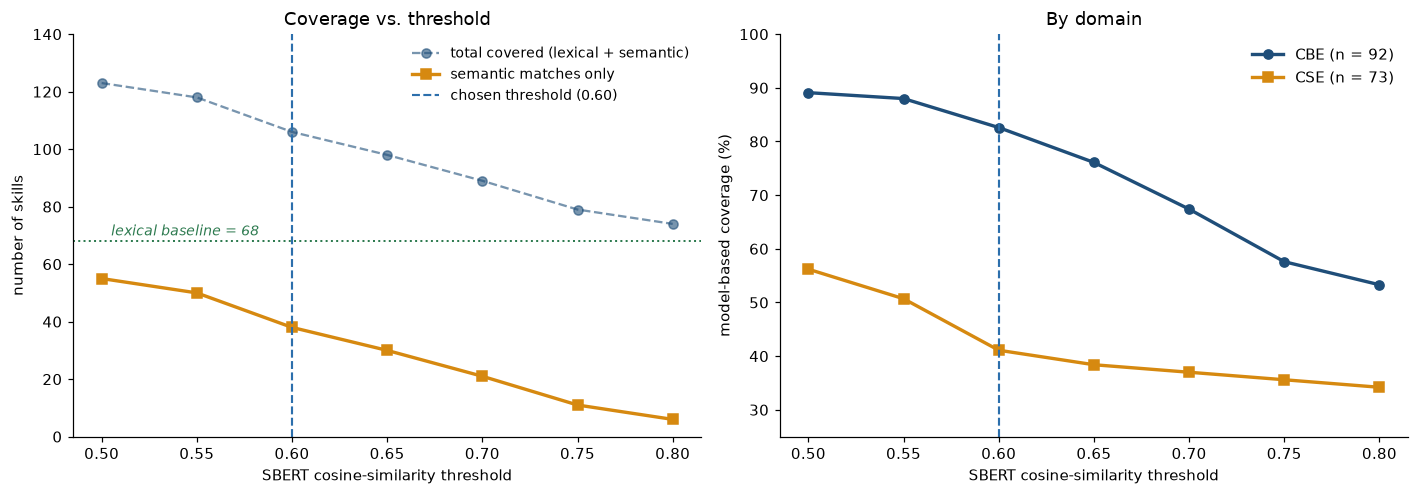

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

ax = axes[0]
ax.plot(sens.threshold, sens.total_covered, "o--", color=BLUE, alpha=0.6, label="total covered (lexical + semantic)")
ax.plot(sens.threshold, sens.semantic_covered, "s-", color=ORANGE, lw=2.2, label="semantic matches only")
ax.axhline(len(lexical), color=GREEN, ls=":", lw=1.3)
ax.text(0.505, len(lexical) + 2, f"lexical baseline = {len(lexical)}", color=GREEN, fontsize=9, style="italic")
ax.axvline(0.60, color="#2C6FAC", ls="--", lw=1.4, label="chosen threshold (0.60)")
ax.set(xlabel="SBERT cosine-similarity threshold", ylabel="number of skills", xticks=thresholds, ylim=(0, 140),
       title="Coverage vs. threshold")
ax.legend(frameon=False, fontsize=9)

ax = axes[1]
for (d, sub), color, marker in zip(by_domain.groupby("domain"), [BLUE, ORANGE], ["o", "s"]):
    n = (df.domain == d).sum()
    ax.plot(sub.threshold, sub.coverage_pct, marker=marker, color=color, lw=2.2, label=f"{d} (n = {n})")
ax.axvline(0.60, color="#2C6FAC", ls="--", lw=1.4)
ax.set(xlabel="SBERT cosine-similarity threshold", ylabel="model-based coverage (%)", xticks=thresholds,
       ylim=(25, 100), title="By domain")
ax.legend(frameon=False)

plt.tight_layout()
plt.savefig("../results/figures/threshold_sensitivity.png")
plt.show()

### Skills near the cutoff

These are the skills whose fate depends on the exact cutoff. Reading their
best-matching topics (in the private data) is why 0.60 was used as a practical
operating point rather than a "proven optimum": just below it some clearly
related matches get rejected, and just above it some looser ones get accepted.

In [5]:
cols = ["skill", "domain", "n_jobs", "similarity_score"]
print("Just below 0.60 (counted as missing by the model):")
print(semantic_pool[semantic_pool.similarity_score < 0.60].nlargest(6, "similarity_score")[cols].to_string(index=False))
print("\nJust above 0.60 (counted as covered by the model):")
print(semantic_pool[(semantic_pool.similarity_score >= 0.60) & (semantic_pool.similarity_score < 0.65)]
      .sort_values("similarity_score")[cols].to_string(index=False))

Just below 0.60 (counted as missing by the model):
                   skill domain  n_jobs  similarity_score
                   Azure    CSE       3            0.5994
Training and Development    CBE       3            0.5958
                     C++    CSE       5            0.5923
                   MySQL    CSE      15            0.5919
     Contract Management    CBE      48            0.5868
               B2B Sales    CBE      31            0.5862

Just above 0.60 (counted as covered by the model):
                         skill domain  n_jobs  similarity_score
              Content Creation    CBE      39            0.6052
                  Unit Testing    CSE      12            0.6062
            Account Management    CBE      30            0.6180
       Customer Needs Analysis    CBE      28            0.6296
              Order Management    CBE      39            0.6321
            Report Preparation    CBE      96            0.6395
Client Relationship Management    CBE      

**Reading it:** going from 0.60 to 0.65 removes 8 semantic matches; going down
to 0.50 adds 17, many of them loose. CBE coverage is more sensitive than CSE
because more business skill–topic pairs sit near the cutoff, while CSE tool
skills tend to either match lexically or score low. The review layer
(notebook 01) exists precisely to deal with these borderline cases.